# Q-Cog quickstart: a two-question survey

Q-Cog models human judgement with **quantum probability**, runs every model on **Qiskit**, and always shows what
a **classical** account of the same situation predicts. This notebook walks through one real survey question at
a time. Run the cells from top to bottom; nothing here needs a network connection or an account.

The survey has two questions:

- **Question A: "Are you satisfied with the economy?"**
- **Question B: "Will you vote for the current administration?"**

Half the respondents are asked A first, half are asked B first. Under classical probability theory that cannot
matter: both answers come from one joint distribution, so the marginal of A is the same either way. The model
here makes the two questions **incompatible** - answering the first one changes the state the second one is put
to - so the order *does* matter, by a computable amount. This is the classic quantum question-order effect.

In [1]:
# Make the library importable when the notebook runs from a checkout
# (do nothing if you installed the package with pip).
import pathlib, sys

for candidate in (pathlib.Path("../src"), pathlib.Path("src")):
    if (candidate / "qcog").exists():
        sys.path.insert(0, str(candidate.resolve()))
        break

import numpy as np
import qcog

print("Q-Cog", qcog.__version__, "|", len(qcog.list_models()), "models available")

Q-Cog 0.1.0 | 23 models available


## 1. The two questions, and the respondent

A quantum model needs three things: **a state** (what the respondent believes), **two questions** (the
measurements), and their **incompatibility** (how much asking one disturbs the other).

- The **state** is an angle. Here the respondent leans in favour of the administration without being decided:
  `|0>` would be firmly against, `|1>` firmly in favour, and an angle in between is a genuine superposition -
  not a hidden answer waiting to be revealed.
- Each **question** is a direction in that same space, and the angle *between the two questions* is what decides
  how much the order matters. Two questions pointing the same way are compatible and the order is irrelevant.

In [2]:
from qcog.core import amplitudes, question

# the respondent: leaning in favour, not decided
belief = amplitudes(np.cos(1.0 / 2), np.sin(1.0 / 2), label="respondent belief")

# the two survey questions, named after what they actually ask
economy = question(0.85, 0.0, "satisfied with the economy", ("satisfied", "dissatisfied"),
                   "Question A: Are you satisfied with the economy?")
vote = question(1.50, 0.0, "vote for the administration", ("would vote", "would not vote"),
                "Question B: Will you vote for the current administration?")

from qcog.core.measurement import incompatibility
print("incompatibility of the two questions:", round(float(incompatibility([economy, vote])), 3))

incompatibility of the two questions: 1.712


## 2. Ask them in both orders

A respondent is either asked A then B, or B then A. `run_sequence` puts the questions to the state in order and
returns the joint distribution of the answers.

In [3]:
from qcog.core import run_sequence

a_then_b = run_sequence(belief, [economy, vote])
b_then_a = run_sequence(belief, [vote, economy])

print("A first:", round(a_then_b.marginal(economy.name)["satisfied"], 3), "say they are satisfied with the economy")
print("B first:", round(b_then_a.marginal(economy.name)["satisfied"], 3), "say they are satisfied with the economy")
print()
print(a_then_b.joint_frame().to_string(index=False))

A first: 0.994 say they are satisfied with the economy
B first: 0.849 say they are satisfied with the economy

satisfied with the economy vote for the administration  probability
                 satisfied                  would vote     0.893000
                 satisfied              would not vote     0.101386
              dissatisfied              would not vote     0.005042
              dissatisfied                  would vote     0.000572


Reading it: the answer to the economy question moves by about 0.14 depending only on what was asked first. The
second row also shows how strongly the first answer predicts the second - which is why nothing classical can
absorb this: a single joint distribution has no way to produce two different marginals for the same question.

## 3. What a classical account is forced to say

A classical model answers both questions from **one** joint distribution. That means the marginal of the first
question cannot depend on which question came first - the law of total probability. The library computes both
sides of that identity and reports the difference.

In [4]:
from qcog.core.classical import law_of_total_probability

classical = law_of_total_probability(
    economy.name, "satisfied",
    a_then_b.marginal(economy.name)["satisfied"],      # measured directly
    b_then_a.marginal(vote.name),                      # and the same thing computed from
    b_then_a.conditional_table(vote.name, economy.name),  # the other order
    conditional_on=vote.name,
)
print("measured directly           :", round(classical.direct, 3))
print("computed from the other order:", round(classical.indirect, 3))
print("difference                   :", round(classical.violation, 3), " (a classical model: exactly 0)")

measured directly           : 0.994
computed from the other order: 0.849
difference                   : 0.145  (a classical model: exactly 0)


## 4. Where the probability comes from

For a second question, the Born rule splits the probability into a **classical part** (what the law of total
probability would give) and an **interference** part. The interference term can be negative, and it is exactly
what makes the two orders disagree.

In [5]:
from qcog.analysis import interference_decomposition

interference = interference_decomposition(belief, economy, vote)
print(interference.summary())

vote for the administration=would vote: p=0.9388 = direct 0.8936 + interference +0.0452; vote for the administration=would not vote: p=0.0612 = direct 0.1064 + interference -0.0452


## 5. A prediction with no free parameters

The **QQ equality** says: the chance of answering both questions "the same way" - both first answers, or both
second answers - does not depend on the order. Here "the same way" means *satisfied and would vote*, or
*dissatisfied and would not vote*; the two questions are worded differently, and the pairing is answer by
answer. No parameter of the model can change this prediction, which is what makes it a test rather than a
description.

In [6]:
from qcog.analysis import qq_equality

qq = qq_equality(a_then_b, b_then_a, economy.name, vote.name)
print(qq.summary())

QQ equality holds: same-answer agreement is 0.8980 in one order and 0.8980 in the other (difference -0.0000, z = +0.00).


## 6. The circuits, with the survey questions on the gates

This is the same calculation drawn as a Qiskit circuit: prepare the belief, rotate into the basis of the first
question, measure, **rotate back**, then ask the second question of the state the first answer left behind. The
rotate-back step is what makes the drawing honest - the second question must be put to the collapsed state, not
to the original one.

The last two circuits are the *branch* versions: no mid-circuit measurement and no reset, just "prepare the state
that follows from this answer, then ask the next question". That is the form to submit to hardware with limited
mid-circuit measurement support, and it produces exactly the same conditional distributions.

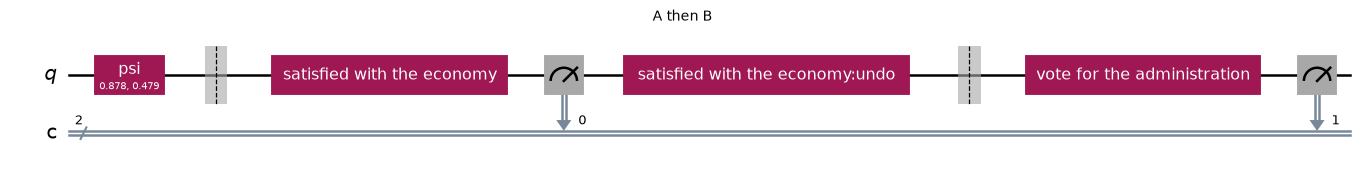

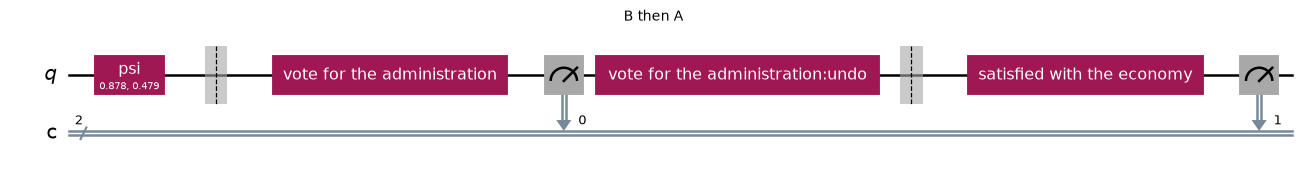

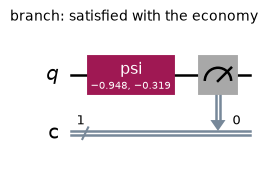

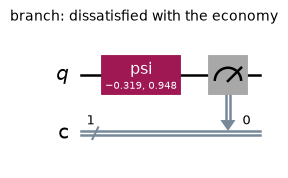

In [7]:
import matplotlib.pyplot as plt
from qcog.circuits import build_prefix_circuit, build_sequence_circuit
from qcog.viz import circuit_figure

circuits = {
    "A then B": build_sequence_circuit(belief, [economy, vote]),
    "B then A": build_sequence_circuit(belief, [vote, economy]),
    "branch: satisfied with the economy": build_prefix_circuit(belief, [economy, vote], ("satisfied",)),
    "branch: dissatisfied with the economy": build_prefix_circuit(belief, [economy, vote], ("dissatisfied",)),
}
for name, circuit in circuits.items():
    display(circuit_figure(circuit, title=name, style="iqp", scale=0.9))
    plt.close("all")

In [8]:
# the same drawings carry a written description, so the picture is not the only way in
figure = circuit_figure(circuits["A then B"], title="A then B")
print(figure._qcog_description)

Circuit qcog_interview: 1 qubit(s), 2 classical bit(s), depth 6, containing 2x barrier, 2x measure, 1x state_preparation, 3x unitary. It contains 6 operations at depth 6 on 1 qubit(s): barrier x2, measure x2, state_preparation x1, unitary x3.


In [9]:
# and the image itself is adjustable: style, gate size, how many gates per line, and format
out = pathlib.Path("../out/economy_vote")
out.mkdir(parents=True, exist_ok=True)
for name, circuit in circuits.items():
    safe = name.replace(" ", "_").replace(":", "")
    circuit_figure(circuit, title=name, style="iqp", scale=0.9,
                   filename=out / f"{safe}.svg")
print("saved:", sorted(path.name for path in out.glob("*.svg")))

saved: ['A_then_B.svg', 'B_then_A.svg', 'branch_dissatisfied_with_the_economy.svg', 'branch_satisfied_with_the_economy.svg']


## 7. The same thing, packaged

The catalogue ships this design as a model, `question-order`, with its own parameters (the angles), its
findings, its sweeps, its figures and its caveats. Everything above is what the model does internally.

In [10]:
model = qcog.get_model("question-order")
result = model.run(state_angle=1.0, angle_a=0.85, angle_b=1.50)

print(result.summary)
print()
for finding in result.findings[:3]:
    print("-", finding)

Order effect 0.145; QQ difference -0.000; incompatibility 1.712.

- Asking the other question first moves p(A = yes) by -0.145 (TV distance 0.1451). Question incompatibility = 1.7117.
- QQ equality holds: same-answer agreement is 0.8980 in one order and 0.8980 in the other (difference -0.0000, z = +0.00).
- Law of total probability violated: p(A=yes) measured directly = 0.9944, but computed from the other order = 0.8493 (violation +0.1451)


### Adjust it

Every parameter is a keyword argument, and `model.params` lists them with their bounds.

In [11]:
for angle in (0.0, 0.85, 1.6):
    run = model.run(state_angle=1.0, angle_a=angle, angle_b=1.50, sweeps=False)
    print(f"economy question angle {angle:4.2f}  ->  {run.summary}")

economy question angle 0.00  ->  Order effect 0.239; QQ difference -0.000; incompatibility 2.821.
economy question angle 0.85  ->  Order effect 0.145; QQ difference -0.000; incompatibility 1.712.
economy question angle 1.60  ->  Order effect 0.024; QQ difference -0.000; incompatibility 0.282.


### The packaged figures

The model's own figure set always contains the results, the order-effect comparison, the interference
decomposition, the classical comparison, the sweeps and the circuit drawings. Each one carries a
plain-language description, so you never have to read a picture to get the numbers.

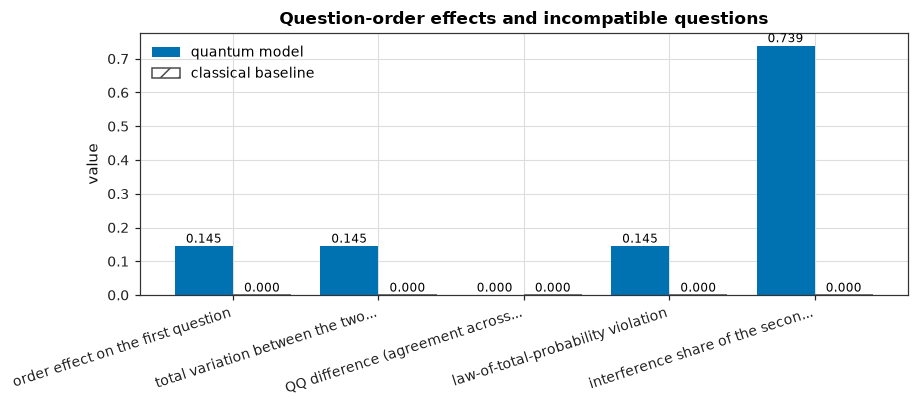

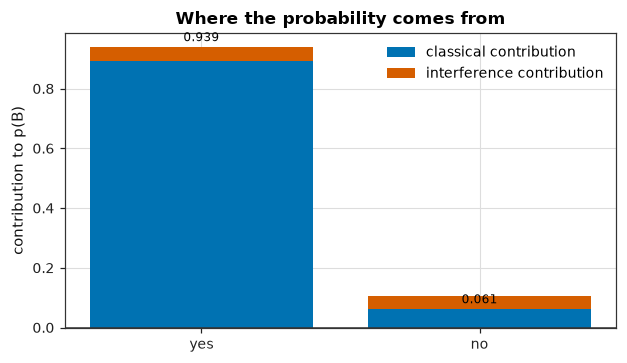

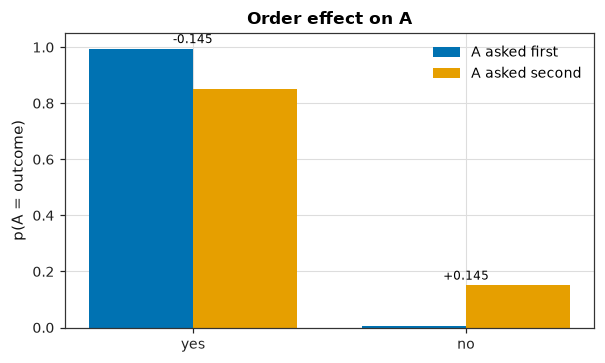

Grouped bar chart comparing the quantum model with the classical baseline on 5 quantities. order effect on the first question: model 0.145 versus classical 0.000; total variation between the two orders: model 0.145 versus classical 0.000; QQ difference (agreement across orders): model 0.000 versus classical 0.000; law-of-total-probability violation: model 0.145 versus classical 0.000; interference share of the second question: model 0.739 versus classical 0.000. Where the classical value is zero the classical account is forced to predict nothing there, so the model's bar is the whole content of that comparison.


In [12]:
figures = model.figures(result)
for name in ("model versus classical baseline", "interference", "order effect"):
    if name in figures:
        display(figures[name])
print(figures["model versus classical baseline"]._qcog_description)
plt.close("all")

## 8. Sample it, the way a survey would

The analytic run is exact. Survey data are not, so the same model can be run through the compiled circuit with a
finite number of respondents per order - and then the parameter-free test comes with a standard error.

In [13]:
sampled = model.run(state_angle=1.0, angle_a=0.85, angle_b=1.50,
                    backend="aer", shots=8000, seed=7)
print(sampled.summary)
print()
print(sampled.findings[1])

Order effect 0.139; QQ difference +0.000; incompatibility 1.712.

QQ equality holds: same-answer agreement is 0.9031 in one order and 0.9027 in the other (difference +0.0004, z = +0.08).


## 9. Save a report, and where to go next

One HTML file, no JavaScript, every chart with a text description and the data table behind it.

In [14]:
path = qcog.write_model_report(model, result, "../out/notebook_report")
print("report written to", path)

report written to ..\out\notebook_report\question-order.html


Where to go next:

- `python examples/06_economy_and_vote.py` - this survey as a script, with the images written out.
- `showcase/run_showcase.py` - a scripted tour of four models with its captured output and reports.
- `qcog list`, `qcog run <slug> --param name=value`, `qcog circuit <slug> --style iqp --format svg` - the same
  things from the command line.
- `streamlit run app/streamlit_app.py` - the interactive explorer, with dark, larger-type, high-contrast and
  text-only modes.

One habit worth keeping: read each model's **caveats**. These models describe *response probabilities*; they do
not claim that the brain is a quantum computer, and the library says so wherever the risk of over-reading is
highest.